# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Caron 2020's ALL malignant manifold is **non-branching**: a scFates PPT tree fit on the joint embedding
returns **0 branch nodes** (2 tips, no fork), and the developmental signatures collapse onto a single
dominant axis rather than a hub radiating to competing arms. The correct topology is therefore a
**principal curve** (ElPiGraph, non-branching by construction) fit on the *joint* embedding — not a
re-embedding (re-embedding an anisotropic strip fabricates folds; the Kürten §4 failure mode).

**Biology before geometry — the decisive check.** The dominant transcriptional axis of these
proliferating blasts is the **cell cycle** (quiescent → G1/S → G2/M). We therefore test explicitly
whether the embryonic-module geography is merely a proliferation shadow: (i) each module's correlation
with a cell-cycle score, (ii) the fraction of each smoothed module's spatial variance explained by cell
cycle, and (iii) whether the **Gast↔pSom cross-repression and the Crest inverse gradient survive after
regressing cell cycle out**. They do — Gast↔pSom stay anti-correlated (r ≈ −0.37 residualized) and Crest
opposes both — so the developmental relationships are cell-cycle-independent, not an artefact. The curve
is rooted at the Gast/pSom-high (developmentally early, quiescent) pole; pseudotime co-varies with the
cell-cycle score (a declared caveat, as in the Zhou 2020 osteosarcoma precedent), because the
proliferative pole is also the Crest-leaning terminus. Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, io, contextlib, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules
Keep all cells on their *original joint embedding coordinates* — no re-embedding. The three embryonic
signatures (Gastrulation / Somitogenesis / Neural-crest) are scored against the shared **union** control
pool and graph-smoothed (3× kNN-connectivity averaging) to read geography rather than 10x per-cell
dropout.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
_,s,_ = np.linalg.svd(c, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')

pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present | mean={adata.obs[lab].mean():+.4f}')
# graph-smooth for geography
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]

whole malignant manifold: 25788 cells on the joint embedding
UMAP aspect ratio (major/minor std): 1.91
Gast: 66/81 genes present | mean=-0.0166
pSom: 77/98 genes present | mean=+0.0003
Crest: 93/104 genes present | mean=-0.0104


### Biology before geometry — is the module geography a cell-cycle artefact?
The blasts are proliferating, so cell cycle is the leading axis. Test whether the developmental
relationships are independent of it: quadratically regress cell cycle out of each raw module, re-smooth,
and re-measure the spatial correlations. If Gast↔pSom anti-correlation and the Crest inverse gradient
survive, the developmental structure is real (cell-cycle is a confound to *declare*, not a NO-GO
trigger — the Zhou 2020 precedent).

In [4]:
g1s = pd.to_numeric(adata.obs['g1s_score'],errors='coerce').fillna(0).values
g2m = pd.to_numeric(adata.obs['g2m_score'],errors='coerce').fillna(0).values
cyc = np.maximum(g1s,g2m); adata.obs['cyc_score']=cyc
print('smoothed spatial correlations (raw geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a],adata.obs[b])[0,1]:+.3f}')
print('module (smoothed) vs cell-cycle score (Spearman rho):')
for m in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(cyc, adata.obs[m]); print(f'  {m}: rho = {rho:+.3f}')
def resid(y,x):
    X=np.vstack([np.ones_like(x),x,x**2]).T; beta,*_=np.linalg.lstsq(X,y,rcond=None); return y-X@beta, 1-np.var(y-X@beta)/np.var(y)
print('\nfraction of smoothed-module variance explained by cell cycle:')
for m in ['Gast','pSom','Crest']:
    _,r2 = resid(adata.obs[m+'_sm'].values, cyc); print(f'  {m}_sm: R2(cyc) = {r2:.3f}')
for m in ['Gast','pSom','Crest']:
    adata.obs[m+'_rc'],_ = resid(adata.obs[m].values.astype(float), cyc)
S = adata.obs[['Gast_rc','pSom_rc','Crest_rc']].values.copy()
for _ in range(3): S = A @ S
for j,m in enumerate(['Gast','pSom','Crest']): adata.obs[m+'_rcsm']=S[:,j]
print('\nspatial correlations AFTER regressing out cell cycle (residualized, smoothed):')
for a,b in [('Gast_rcsm','pSom_rcsm'),('Crest_rcsm','Gast_rcsm'),('Crest_rcsm','pSom_rcsm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a],adata.obs[b])[0,1]:+.3f}')
print('-> Gast<->pSom cross-repression and Crest inverse gradient survive cell-cycle removal:')
print('   the developmental geography is cell-cycle-independent; cell cycle is a declared caveat, not a NO-GO.')

smoothed spatial correlations (raw geography):
  Gast_sm vs pSom_sm: r = -0.451
  Crest_sm vs Gast_sm: r = -0.218
  Crest_sm vs pSom_sm: r = -0.718
module (smoothed) vs cell-cycle score (Spearman rho):
  Gast_sm: rho = -0.573
  pSom_sm: rho = +0.065
  Crest_sm: rho = +0.132

fraction of smoothed-module variance explained by cell cycle:
  Gast_sm: R2(cyc) = 0.373
  pSom_sm: R2(cyc) = 0.173
  Crest_sm: R2(cyc) = 0.111

spatial correlations AFTER regressing out cell cycle (residualized, smoothed):
  Gast_rcsm vs pSom_rcsm: r = -0.372
  Crest_rcsm vs Gast_rcsm: r = -0.431
  Crest_rcsm vs pSom_rcsm: r = -0.653
-> Gast<->pSom cross-repression and Crest inverse gradient survive cell-cycle removal:
   the developmental geography is cell-cycle-independent; cell cycle is a declared caveat, not a NO-GO.


### Honest topology test — PPT tree returns no branch node
Fit a scFates PPT **tree** on the joint embedding and count forks. A genuine bifurcation would show
branch nodes (degree ≥ 3); here there are none, so the manifold is non-branching and a principal curve
is the correct object (do not fit a tree on a strip; Chen2020 attempt-3 failure mode). The tree edges
are rendered over the cell-cycle-colored embedding so the topology is judged on the embedding, not a
scalar.

PPT tree: 2 tips, 0 forks (branch nodes) -> NON-BRANCHING


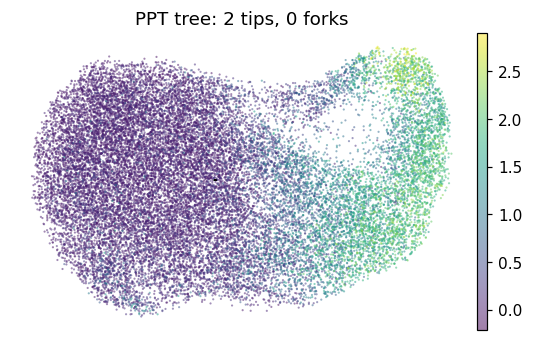

In [5]:
ad_tree = adata.copy()
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.tree(ad_tree, method='ppt', Nodes=100, ppt_lambda=2000, ppt_sigma=5,
                use_rep='X_umap', seed=SEED, plot=False)
B = np.asarray(ad_tree.uns['graph']['B']); deg=(B>0).sum(0)
tips=int((deg==1).sum()); forks=int((deg>=3).sum())
print(f'PPT tree: {tips} tips, {forks} forks (branch nodes) -> {"BRANCHING" if forks else "NON-BRANCHING"}')
F = ad_tree.uns['graph']['F'].T
plot = ad_tree.copy(); plot.obsm['X_umap']=plot.obsm['X_umap_lin']
# rotate node coords into the house orientation too
xy0 = ad_tree.obsm['X_umap']; cc = xy0 - xy0.mean(0)
_,_,vt = np.linalg.svd(cc, full_matrices=False); thr = np.arctan2(vt[0,1],vt[0,0])
Rm = np.array([[np.cos(-thr),-np.sin(-thr)],[np.sin(-thr),np.cos(-thr)]])
sgn = 1 if np.average((cc@Rm.T)[:,0], weights=adata.obs['cyc_score']) >= 0 else -1
Fr = (F - xy0.mean(0)) @ Rm.T; Fr[:,0]*=sgn
fig,ax=plt.subplots(figsize=(5,3.2))
sc.pl.umap(plot,color='cyc_score',cmap='viridis',size=8,alpha=.5,frameon=False,show=False,ax=ax,title=f'PPT tree: {tips} tips, {forks} forks')
ii,jj=np.where(np.triu(B>0))
for a,b in zip(ii,jj): ax.plot([Fr[a,0],Fr[b,0]],[Fr[a,1],Fr[b,1]],'k-',lw=.7)
if forks: ax.scatter(Fr[deg>=3,0],Fr[deg>=3,1],c='red',s=40,zorder=5)
fig.tight_layout()

### Fit the principal curve (ElPiGraph) and verify it is fold-free
`Nodes/epg_lambda/epg_mu` give a fold-free monotone backbone: a node self-approach ratio > 1 (minimum
distance between graph-non-adjacent nodes, in units of median edge length) certifies the curve does not
fold back on itself. The curve edges are rendered below so continuity is judged on the embedding
directly, not a UMAP-neighbour metric (Kürten §4).

In [6]:
sub = adata.copy()
def fold_diag(ad):
    B=np.asarray(ad.uns['graph']['B']); F=ad.uns['graph']['F'].T
    G=shortest_path(sp.csr_matrix((B>0).astype(int)),unweighted=True)
    ii,jj=np.where(np.triu(B>0)); med=np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin=np.inf
    for a in range(F.shape[0]):
        for b in range(a+1,F.shape[0]):
            if G[a,b]>=3: dmin=min(dmin,np.sqrt(((F[a]-F[b])**2).sum()))
    tips=int(((B>0).sum(0)==1).sum()); forks=int(((B>0).sum(0)>=3).sum())
    return dmin/med,tips,forks
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa,tips,forks = fold_diag(sub)
print(f'curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks==0 and sa>1, "topology check failed"


curve: 2 tips, 0 forks | fold self-approach ratio = 3.00 (>1 = fold-free)


### Derive the root (developmental order) and pseudotime
Root at the curve tip where Gast+pSom is highest and Crest lowest — the developmental origin (Crest is
*late*, so it never roots; the Kürten root lesson). Pseudotime then flows toward the Crest-leaning
terminus. We report the co-variation of pseudotime with the cell-cycle score as a declared property of
the biology (the proliferative pole is the terminus), not a re-derivation of the axis.

In [7]:
B=np.asarray(sub.uns['graph']['B']); tps=np.where((B>0).sum(0)==1)[0]
R=np.asarray(sub.obsm['X_R']); hard=R.argmax(1)
D=shortest_path(sp.csr_matrix((B>0).astype(int)),unweighted=True)
info={}
for tp in tps:
    m=np.isin(hard,np.where(D[tp]<=3)[0])
    info[tp]=(sub.obs['Gast_sm'][m].mean(),sub.obs['pSom_sm'][m].mean(),sub.obs['Crest_sm'][m].mean(),sub.obs['cyc_score'].values[m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f} cyc={info[tp][3]:.3f}')
root=int(max(tps,key=lambda tp:info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t=sub.obs['t'].values; tn=(t-t.min())/(t.max()-t.min())
print('\ngradient along pseudotime (Spearman rho, smoothed):')
for s_ in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_=spearmanr(t,sub.obs[s_]); print(f'  {s_}: rho={rho:+.3f}')
rho_c,_=spearmanr(t,sub.obs['cyc_score']); print(f'  cyc_score: rho={rho_c:+.3f} (declared caveat: proliferative pole = terminus)')

tip 0: Gast=-0.0101 pSom=-0.0014 Crest=-0.0145 cyc=0.060
tip 2: Gast=-0.0272 pSom=+0.0071 Crest=-0.0164 cyc=1.509
derived root = tip 0 (Gast/pSom-high, Crest-low developmental origin)

gradient along pseudotime (Spearman rho, smoothed):
  Gast_sm: rho=-0.716
  pSom_sm: rho=+0.028
  Crest_sm: rho=+0.326
  cyc_score: rho=+0.692 (declared caveat: proliferative pole = terminus)


### House orientation (re-used from 01, verified against pseudotime)
The house orientation (rigid rotation to horizontal, proliferative pole on the right, stored as
`X_umap_lin` in 01) is re-used unchanged. Verify it is now pseudotime-consistent: corr(`X_umap_lin`
x-axis, pseudotime) should be strongly positive (developmental origin on the left, low pseudotime).

In [8]:
r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], sub.obs['t'].values)[0,1])
print(f'corr(X_umap_lin x, pseudotime) = {r:+.2f} (positive: origin left, terminus right)')
assert abs(r) > 0.5, 'stored orientation not pseudotime-consistent'
if r < 0:
    sub.obsm['X_umap_lin'][:,0] = -sub.obsm['X_umap_lin'][:,0]
    print('flipped X_umap_lin x so low pseudotime is on the left')

corr(X_umap_lin x, pseudotime) = +0.99 (positive: origin left, terminus right)


### Save manifold + trajectory figure (deliverable) — house `(3.5,1.5)` pseudotime strip

saved manifold.h5ad + manifold.pdf | root tip 0


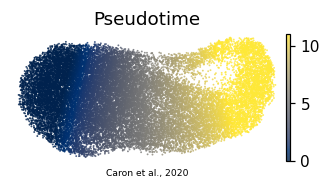

In [9]:
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi=np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi=np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap']=plot.obsm['X_umap_lin']
fig,ax=plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot,color='t',cmap='cividis',size=6,alpha=.8,colorbar_loc='right',
           frameon=False,show=False,ax=ax,title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Caron et al., 2020',ha='center',transform=ax.transAxes,size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'),bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf | root tip', root)